## CA01 - Statistical Analysis 

### Daily Wellness and Performance 

### Web form - https://docs.google.com/forms/d/e/1FAIpQLScQsShy4GjzI6Np9ydrJ83kdp1VMr0MHepEgPIGFGyQLqPjLA/viewform?usp=dialog

#### CSV file available on github and submitted to Moodle

In [1]:
#Libraries
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import seaborn as sns 

In [2]:
#Dataset
df_original = pd.read_csv("Data_CA01.csv")

In [3]:
df_original.tail()

,Timestamp,How old are you?,Do you do any kind of exercise?,How many days per week do you exercise?,"On average, how many hours do you sleep per night?",How would you rate your sleep?,How consistent is your bedtime?,Do you track calories or manage your weight?,How many supplements do you take per day?,How many litres of water do you drink every day?,"Do you drink coffee? If so, how many cups of coffee per day?","If you had the opportunity to use GLP-1 medication to lose weight, would you?",How would you rate your daily energy and productivity levels?,How many hours of phone screen time do you have every day?
42,2026/10/01 7:20:56 pm CET,24,Yes,6,8.0,3,Varies a lot,3,2,2.0,2,No,3,3.0
43,2026/10/01 9:32:19 pm CET,33,Yes,2,7.0,4,Varies a lot,3,6,1.5,2,No,2,3.0
44,2026/10/02 1:34:11 pm CET,26,Yes,3,6.5,4,Always the same,2,2,2.0,1,No,4,4.0
45,2026/10/03 11:49:31 am CET,53,Yes,5,6.0,3,I don't have a sleep routine,3,5,2.0,2,Yes,4,3.0
46,2026/10/03 11:54:37 am CET,64,Yes,2,5.6,3,I don't have a sleep routine,3,5,2.0,3,Yes,3,3.6


In [4]:
df = df_original.copy() #Creating a copy of my origianl data frame

In [5]:
df = df.rename(columns={"How old are you?": "Age",
                        "Do you do any kind of exercise? ": "Exercise_YesNo",
                        "How many days per week do you exercise? ": "Exercise_Days",
                        "On average, how many hours do you sleep per night? ": "Sleep_Hours",
                        "How would you rate your sleep?": "Sleep_Score",
                        "How consistent is your bedtime?": "Bedtime_Rate",
                        "Do you track calories or manage your weight? ": "Track_Calories?",
                        "How many supplements do you take per day?": "Supplement_Per_Day",
                        "How many litres of water do you drink every day? ":"Water_Liters",
                        "Do you drink coffee? If so, how many cups of coffee per day? ": "Coffee_Amount",
                        "If you had the opportunity to use GLP-1 medication to lose weight, would you? ": "GLP1_YesNo",
                        "How would you rate your daily energy and productivity levels?": "Daily_Energy",
                        "How many hours of phone screen time do you have every day?": "Screen_Time",})

df = df.drop(columns=["Timestamp"])
df.head()

,Age,Exercise_YesNo,Exercise_Days,Sleep_Hours,Sleep_Score,Bedtime_Rate,Track_Calories?,Supplement_Per_Day,Water_Liters,Coffee_Amount,GLP1_YesNo,Daily_Energy,Screen_Time
0,28,Yes,5,8.0,4,Always the same,4,2,2.0,1,Yes,3,2.5
1,30,Yes,2,8.0,4,Varies a lot,2,1,1.0,2,No,2,6.0
2,26,Yes,2,7.0,2,I don't have a sleep routine,2,0,2.0,0,No,2,6.0
3,46,Yes,3,8.0,5,Varies a lot,5,2,8.0,1,No,3,4.0
4,40,Yes,2,6.0,3,Varies a lot,3,2,1.5,2,No,2,4.0


In [11]:
numeric_columns = ["Age", "Exercise_Days", "Sleep_Hours", "Sleep_Score", "Track_Calories?", "Supplement_Per_Day", "Water_Liters", "Coffee_Amount", "Daily_Energy", "Screen_Time"]

categorical_columns = ["Exercise_YesNo", "Bedtime_Rate", "GLP1_YesNo"]

print("Rows:", len(df))
print("Columns:", len(df.columns))


Rows: 47
Columns: 13


### Descriptive Statistics

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 47 non-null     int64  
 1   Exercise_YesNo      47 non-null     str    
 2   Exercise_Days       47 non-null     int64  
 3   Sleep_Hours         47 non-null     float64
 4   Sleep_Score         47 non-null     int64  
 5   Bedtime_Rate        47 non-null     str    
 6   Track_Calories?     47 non-null     int64  
 7   Supplement_Per_Day  47 non-null     int64  
 8   Water_Liters        47 non-null     float64
 9   Coffee_Amount       47 non-null     int64  
 10  GLP1_YesNo          47 non-null     str    
 11  Daily_Energy        47 non-null     int64  
 12  Screen_Time         47 non-null     float64
dtypes: float64(3), int64(7), str(3)
memory usage: 5.9 KB


In [22]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,47.0,37.723404,12.303591,24.0,28.0,33.0,44.0,64.0
Exercise_Days,47.0,3.000000,1.853317,0.0,2.0,3.0,5.0,7.0
Sleep_Hours,47.0,6.641489,1.002948,4.0,6.0,7.0,7.0,8.0
Sleep_Score,47.0,3.319149,1.002310,1.0,3.0,3.0,4.0,5.0
Track_Calories?,47.0,2.659574,1.355770,1.0,2.0,2.0,4.0,5.0
Supplement_Per_Day,47.0,2.255319,2.047990,0.0,0.5,2.0,3.5,7.0
Water_Liters,47.0,1.897872,1.139697,0.0,1.5,2.0,2.0,8.0
Coffee_Amount,47.0,1.872340,1.689057,0.0,1.0,2.0,2.5,10.0
Daily_Energy,47.0,3.340426,0.787859,2.0,3.0,3.0,4.0,5.0
Screen_Time,47.0,3.597872,1.583267,0.5,2.5,3.6,4.0,9.0


In [19]:
numeric_summary = pd.DataFrame({'Mean': df[numeric_columns].mean(),
                        'Median': df[numeric_columns].median(),
                        'Mode': df[numeric_columns].mode().iloc[0]})
numeric_summary.round(2)

,Mean,Median,Mode
Age,37.72,33.0,28.0
Exercise_Days,3.00,3.0,2.0
Sleep_Hours,6.64,7.0,7.0
Sleep_Score,3.32,3.0,4.0
Track_Calories?,2.66,2.0,2.0
Supplement_Per_Day,2.26,2.0,2.0
Water_Liters,1.90,2.0,2.0
Coffee_Amount,1.87,2.0,2.0
Daily_Energy,3.34,3.0,3.0
Screen_Time,3.60,3.6,4.0


In [16]:
df[categorical_columns].describe()

,Exercise_YesNo,Bedtime_Rate,GLP1_YesNo
count,47,47,47
unique,2,3,2
top,Yes,Always the same,No
freq,39,20,33


In [20]:
for column in categorical_columns: 
    print(df[column].value_counts())
    print()

Exercise_YesNo
Yes    39
No      8
Name: count, dtype: int64

Bedtime_Rate
Always the same                 20
Varies a lot                    18
I don't have a sleep routine     9
Name: count, dtype: int64

GLP1_YesNo
No     33
Yes    14
Name: count, dtype: int64



In [7]:
df.isnull().sum() #checking if any nulls

Age                   0
Exercise_YesNo        0
Exercise_Days         0
Sleep_Hours           0
Sleep_Score           0
Bedtime_Rate          0
Track_Calories?       0
Supplement_Per_Day    0
Water_Liters          0
Coffee_Amount         0
GLP1_YesNo            0
Daily_Energy          0
Screen_Time           0
dtype: int64

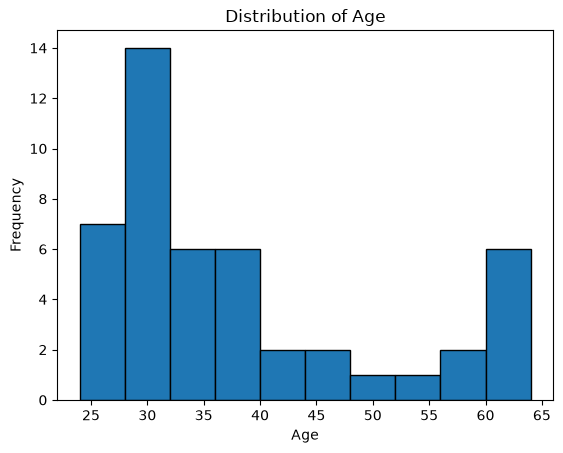

In [31]:
plt.hist(df['Age'], bins=10, edgecolor='black')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

Text(0.5, 1.0, 'Investigation - Distribution of Age')

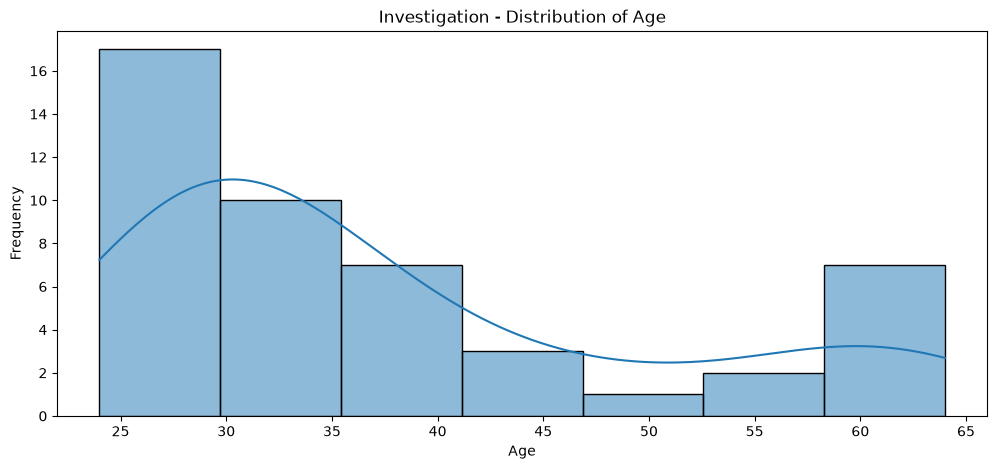

In [36]:
#Checking bimodal distribution of age
plt.figure(figsize = (12,5))
sns.histplot(df["Age"],kde=True)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Investigation - Distribution of Age")

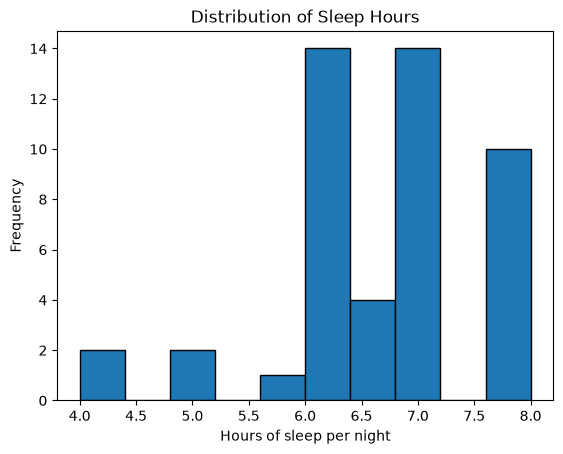

In [30]:
plt.hist(df["Sleep_Hours"], bins = 10, edgecolor = "black")
plt.title("Distribution of Sleep Hours")
plt.xlabel("Hours of sleep per night")
plt.ylabel("Frequency")
plt.show()

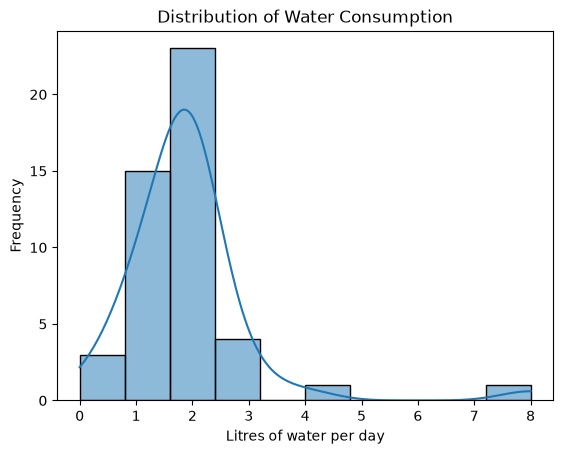

In [42]:
sns.histplot(df["Water_Liters"], bins=10, kde=True, edgecolor='black')
plt.title('Distribution of Water Consumption')
plt.xlabel('Litres of water per day')
plt.ylabel('Frequency')
plt.show()

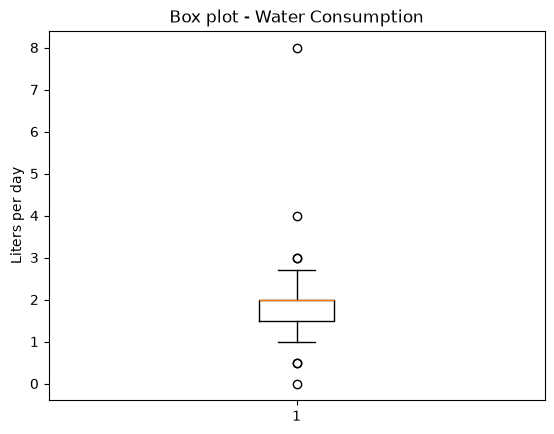

In [43]:
plt.boxplot(df["Water_Liters"])
plt.title("Box plot - Water Consumption")
plt.ylabel("Liters per day")
plt.show()

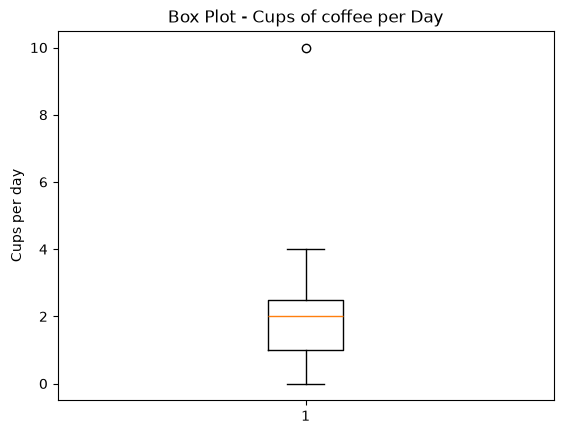

In [45]:
plt.boxplot(df["Coffee_Amount"])
plt.title("Box Plot - Cups of coffee per Day")
plt.ylabel("Cups per day")
plt.show()

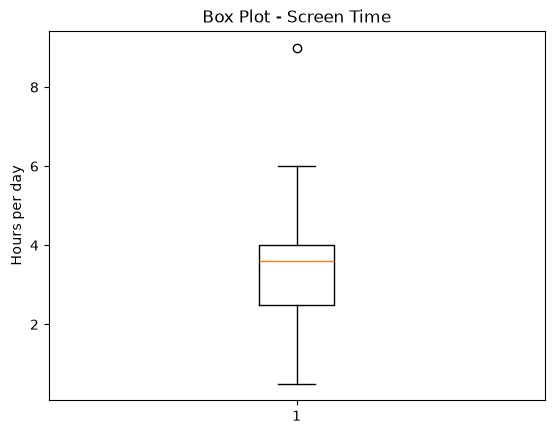

In [46]:
plt.boxplot(df["Screen_Time"])
plt.title("Box Plot - Screen Time")
plt.ylabel("Hours per day")
plt.show()

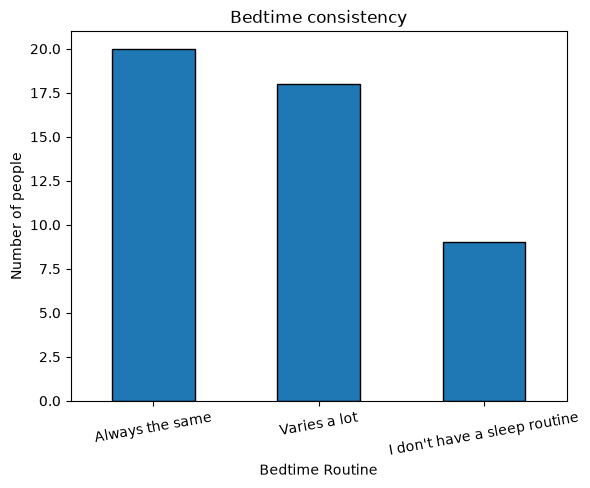

In [53]:
df["Bedtime_Rate"].value_counts().plot(kind="bar", edgecolor= "black")
plt.title("Bedtime consistency")
plt.xlabel("Bedtime Routine")
plt.ylabel("Number of people")
plt.xticks(rotation=10)
plt.show()

### Normality Test

In [57]:
for column in numeric_columns:
    stat, p_value = stats.shapiro(df[column])
    print(f"{column} - stat: {stat: .3f}, p-value: {p_value: .4f}")

    if p_value >=0.05:
        print("Sample is normally distributed.")
    else:
        print("Sample NOT normally distributed.")
    print()

Age - stat:  0.821, p-value:  0.0000
Sample NOT normally distributed.

Exercise_Days - stat:  0.940, p-value:  0.0182
Sample NOT normally distributed.

Sleep_Hours - stat:  0.900, p-value:  0.0007
Sample NOT normally distributed.

Sleep_Score - stat:  0.894, p-value:  0.0005
Sample NOT normally distributed.

Track_Calories? - stat:  0.883, p-value:  0.0002
Sample NOT normally distributed.

Supplement_Per_Day - stat:  0.882, p-value:  0.0002
Sample NOT normally distributed.

Water_Liters - stat:  0.657, p-value:  0.0000
Sample NOT normally distributed.

Coffee_Amount - stat:  0.772, p-value:  0.0000
Sample NOT normally distributed.

Daily_Energy - stat:  0.842, p-value:  0.0000
Sample NOT normally distributed.

Screen_Time - stat:  0.930, p-value:  0.0078
Sample NOT normally distributed.

